# 3. Croisement : accès des logements aux commerces alimentaires

À partir des deux fichiers nettoyés (`data/processed/`), on calcule pour chaque vente
la distance au commerce le plus proche de chaque catégorie, puis un indice d'accessibilité
par catégorie. On écrit enfin les tableaux de résultats présentés dans le rapport
(`outputs/tables/`).

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from src import config

In [2]:
bpe = gpd.read_parquet(config.DOSSIER_DONNEES / "bpe_alim_2025.parquet")
dvf = gpd.read_parquet(config.DOSSIER_DONNEES / "dvf_ventes_2025.parquet")

print("BPE :", bpe.shape, "| EPSG", bpe.crs.to_epsg())
print("DVF :", dvf.shape, "| EPSG", dvf.crs.to_epsg())

BPE : (135587, 21) | EPSG 2154
DVF : (810517, 17) | EPSG 2154


On distingue quatre catégories de commerces : les hypermarchés (B104), les supermarchés (B105),
les commerces de proximité généralistes (supérettes et épiceries, B201 et B202), et les commerces
alimentaires spécialisés (boulangeries, boucheries, poissonneries…, B204 à B210).

In [3]:
codes_b2 = sorted(c for c in bpe["TYPEQU"].unique() if c.startswith("B2"))

types_commerces = {
    "hyper": ["B104"],
    "super": ["B105"],
    "proximite": ["B201", "B202"],
    "specialise": [c for c in codes_b2 if c not in ["B201", "B202"]],
}

for nom, codes in types_commerces.items():
    print(nom, ":", codes, "->", bpe["TYPEQU"].isin(codes).sum(), "commerces")

hyper : ['B104'] -> 2081 commerces
super : ['B105'] -> 12106 commerces
proximite : ['B201', 'B202'] -> 30575 commerces
specialise : ['B204', 'B205', 'B206', 'B207', 'B208', 'B209', 'B210'] -> 90825 commerces


In [4]:
for nom, codes in types_commerces.items():
    commerces = bpe.loc[bpe["TYPEQU"].isin(codes), ["geometry"]]

    plus_proche_type = gpd.sjoin_nearest(
        dvf[["geometry"]], commerces,
        how="left", distance_col=f"dist_{nom}",
    )
    plus_proche_type = plus_proche_type[~plus_proche_type.index.duplicated()]

    dvf[f"dist_{nom}"] = plus_proche_type[f"dist_{nom}"]
    print(f"{nom} : distance médiane {dvf[f'dist_{nom}'].median():.0f} m")

hyper : distance médiane 2283 m
super : distance médiane 755 m
proximite : distance médiane 490 m
specialise : distance médiane 295 m


In [5]:
colonnes_dist = [f"dist_{nom}" for nom in types_commerces]

dvf["dist_plus_proche"] = dvf[colonnes_dist].min(axis=1)
dvf["type_plus_proche"] = dvf[colonnes_dist].idxmin(axis=1).str.replace("dist_", "")

dvf["type_plus_proche"].value_counts(normalize=True).round(3)

type_plus_proche
specialise    0.628
proximite     0.251
super         0.108
hyper         0.013
Name: proportion, dtype: float64

In [6]:
colonnes_dist = [f"dist_{nom}" for nom in types_commerces] + ["dist_plus_proche"]
dvf[colonnes_dist].describe(percentiles=[0.1, 0.5, 0.9]).round(0)

,dist_hyper,dist_super,dist_proximite,dist_specialise,dist_plus_proche
count,810517.0,810517.0,810517.0,810517.0,810517.0
mean,4956.0,1917.0,1312.0,731.0,625.0
std,5958.0,2633.0,1908.0,1148.0,1016.0
min,0.0,0.0,0.0,0.0,0.0
10%,649.0,170.0,85.0,59.0,47.0
50%,2283.0,755.0,490.0,295.0,248.0
90%,13119.0,5690.0,3968.0,2138.0,1799.0
max,53570.0,30676.0,21261.0,16233.0,14433.0


La moitié des logements vendus se trouvent à moins de 300 m environ d'un commerce alimentaire
spécialisé, à moins de 500 m d'une supérette ou d'une épicerie, à moins de 750 m d'un supermarché
et à un peu plus de 2 km d'un hypermarché. Pour 65 % des logements, le commerce alimentaire
le plus proche est un commerce spécialisé, très souvent une boulangerie.

In [7]:
# La densité vient de la grille INSEE, ajoutée lors du nettoyage du DVF
assert dvf["DENS7"].notna().all()
dvf["LIBDENS7"].value_counts()

LIBDENS7
Grands centres urbains            306086
Rural à habitat dispersé          119616
Bourgs ruraux                     119533
Centres urbains intermédiaires    116344
Ceintures urbaines                 70249
Petites villes                     54184
Rural à habitat très dispersé      24505
Name: count, dtype: int64

In [8]:
seuil_suspect = dvf.groupby("DENS7")["dist_plus_proche"].transform(lambda x: x.quantile(0.999))
suspects = dvf[dvf["dist_plus_proche"] > seuil_suspect]

print("Ventes suspectes :", len(suspects))
suspects.sort_values("dist_plus_proche", ascending=False)[
    ["nom_commune", "code_commune", "DENS7", "dist_plus_proche", "longitude", "latitude"]
].head(20)

Ventes suspectes : 805


,nom_commune,code_commune,DENS7,dist_plus_proche,longitude,latitude
1562027,Bourriot-Bergonce,40053,7,14432.652948,-0.186952,44.121401
1577169,Bourriot-Bergonce,40053,7,14368.511282,-0.191450,44.124067
1557678,Bourriot-Bergonce,40053,7,14349.618223,-0.160891,44.116882
1555598,Bourriot-Bergonce,40053,7,14251.599854,-0.198201,44.152456
1973506,Saint-Ouen-Domprot,51508,6,13427.651378,4.412537,48.609575
1974353,Saint-Ouen-Domprot,51508,6,13252.786781,4.407830,48.610175
1966724,Saint-Ouen-Domprot,51508,6,12731.572118,4.408602,48.603513
113290,Tartonne,04214,7,12153.549315,6.390606,44.068018
1569249,Bourriot-Bergonce,40053,7,12122.914135,-0.252357,44.131985
1562834,Losse,40158,7,12061.305197,-0.101843,44.098520


**Contrôle des distances.** Après le retrait des coordonnées aberrantes lors du nettoyage, les
distances au commerce le plus proche les plus élevées sont de l'ordre de 15 km. Elles concernent
des communes rurales isolées (par exemple Bourriot-Bergonce dans les Landes, ou Borce dans les
Pyrénées) : ce sont des situations réelles d'éloignement, et non des erreurs de géolocalisation.

In [9]:
categories = list(types_commerces)

def calculer_rayons(q):
    """Rayon par niveau de densité et par catégorie : quantile q de la distance au plus proche."""
    return pd.DataFrame({
        cat: dvf.groupby("DENS7")[f"dist_{cat}"].quantile(q) for cat in categories
    })

rayons = calculer_rayons(0.99)
rayons.round(0)

,hyper,super,proximite,specialise
DENS7,,,,
1,4594.0,2018.0,1614.0,932.0
2,13729.0,3502.0,2948.0,1733.0
3,23044.0,6337.0,5789.0,2908.0
4,12318.0,5377.0,4602.0,2505.0
5,30599.0,11137.0,9474.0,4231.0
6,32771.0,15228.0,11050.0,7005.0
7,38198.0,17929.0,11912.0,8758.0


Les rayons augmentent quand la densité diminue : dans les grands centres urbains, 99 % des
logements ont un supermarché à moins de 2 km environ, contre près de 18 km dans le rural à
habitat très dispersé. Ils sont aussi bien plus grands pour les hypermarchés, plus rares,
que pour les commerces de proximité.

In [10]:
TAILLE_BLOC = 5_000

def indice_lineaire(xy_ventes, rayon_vente, arbre, rayons_commerces, comptage=False):
    """Somme sur les commerces de max(0, 1 - d/R), avec R = min(rayon du logement, rayon du commerce)."""
    resultat = np.zeros(len(xy_ventes))
    for debut in range(0, len(xy_ventes), TAILLE_BLOC):
        bloc = xy_ventes[debut:debut + TAILLE_BLOC]
        paires = cKDTree(bloc).sparse_distance_matrix(
            arbre, max_distance=rayon_vente, output_type="ndarray"
        )
        rayon_paire = np.minimum(rayon_vente, rayons_commerces[paires["j"]])
        if comptage:
            contributions = (paires["v"] < rayon_paire).astype(int)
        else:
            contributions = np.clip(1 - paires["v"] / rayon_paire, 0, None)
        resultat[debut:debut + len(bloc)] = np.bincount(
            paires["i"], weights=contributions, minlength=len(bloc)
        )
    return resultat


def calculer_indices(df, rayons_q, suffixe="", comptage=False):
    """Calcule l'indice de chaque catégorie pour les ventes de df, avec les rayons donnés."""
    resultats = pd.DataFrame(index=df.index)
    for cat in categories:
        commerces = bpe[bpe["TYPEQU"].isin(types_commerces[cat])]
        arbre = cKDTree(np.column_stack([commerces.geometry.x, commerces.geometry.y]))
        rayons_commerces = commerces["DENS7"].map(rayons_q[cat]).to_numpy(dtype=float)

        colonne = f"{'nb_rayon' if comptage else 'acces'}_{cat}{suffixe}"
        resultats[colonne] = np.nan
        for niveau, rayon in rayons_q[cat].items():
            masque = (df["DENS7"] == niveau).to_numpy()
            if masque.sum() == 0:
                continue
            xy = np.column_stack([df.geometry.x[masque], df.geometry.y[masque]])
            resultats.loc[masque, colonne] = indice_lineaire(xy, rayon, arbre, rayons_commerces, comptage=comptage)
        print(f"{colonne} : terminé")
    return resultats


assert bpe["DENS7"].isin(rayons.index).all(), "Des commerces ont un niveau de densité sans rayon"

In [11]:
indices = calculer_indices(dvf, rayons)
dvf[indices.columns] = indices

acces_hyper : terminé
acces_super : terminé
acces_proximite : terminé
acces_specialise : terminé


In [12]:
colonnes_acces = [f"acces_{cat}" for cat in categories]

print("Valeurs manquantes :")
print(dvf[colonnes_acces].isna().sum(), "\n")

print("Part de logements sans aucun commerce de la catégorie dans le rayon :")
(dvf[colonnes_acces] == 0).groupby(dvf["DENS7"]).mean().round(3)

Valeurs manquantes :
acces_hyper         0
acces_super         0
acces_proximite     0
acces_specialise    0
dtype: int64 

Part de logements sans aucun commerce de la catégorie dans le rayon :


,acces_hyper,acces_super,acces_proximite,acces_specialise
DENS7,,,,
1,0.010,0.010,0.010,0.010
2,0.013,0.011,0.013,0.010
3,0.039,0.014,0.013,0.010
4,0.035,0.028,0.032,0.014
5,0.047,0.027,0.017,0.013
6,0.060,0.059,0.020,0.028
7,0.155,0.109,0.023,0.053


Aucun indice ne manque. Par construction du rayon (99e percentile de la distance au plus proche),
environ 1 % des logements de chaque niveau de densité n'ont aucun commerce de la catégorie dans
leur rayon, et ont donc un indice nul. Cette part est un peu plus élevée pour les hypermarchés
dans le rural très dispersé, en raison de la règle du plus petit rayon : un hypermarché situé
en zone plus dense compte avec le rayon, plus court, de sa propre zone.

In [13]:
dvf.groupby("DENS7")[colonnes_acces].median().round(2)

,acces_hyper,acces_super,acces_proximite,acces_specialise
DENS7,,,,
1,2.30,4.31,9.52,7.55
2,2.29,3.14,6.19,11.21
3,1.75,2.40,3.48,8.57
4,1.60,1.77,2.14,4.11
5,1.51,1.62,2.42,3.73
6,1.20,1.20,1.97,2.23
7,0.67,0.71,1.39,1.34


L'accès médian à chaque catégorie de commerce diminue globalement avec la densité, des grands
centres urbains au rural très dispersé. Les commerces de proximité et spécialisés sont ceux dont
l'accès varie le plus entre territoires ; l'accès aux hypermarchés est plus homogène, car ils sont
implantés en périphérie des villes et desservent de larges zones.
Les valeurs de l'indice ne sont pas comparables d'un niveau de densité à l'autre, puisque les rayons
diffèrent : on raisonne donc ensuite sur le **rang** de chaque logement à l'intérieur de son niveau
de densité (0 = le moins bien desservi, 1 = le mieux desservi).

In [14]:
for cat in categories:
    dvf[f"rang_{cat}"] = dvf.groupby("DENS7")[f"acces_{cat}"].rank(pct=True)

In [15]:
echantillon = dvf.sample(100_000, random_state=0)

sensibilite = calculer_indices(echantillon, calculer_rayons(0.95), "_p95").join(
    calculer_indices(echantillon, calculer_rayons(0.90), "_p90")
)

pd.DataFrame([
    {
        "categorie": cat,
        "p99 vs p95": echantillon[f"acces_{cat}"].corr(sensibilite[f"acces_{cat}_p95"], method="spearman"),
        "p99 vs p90": echantillon[f"acces_{cat}"].corr(sensibilite[f"acces_{cat}_p90"], method="spearman"),
    }
    for cat in categories
]).round(3)

acces_hyper_p95 : terminé
acces_super_p95 : terminé
acces_proximite_p95 : terminé
acces_specialise_p95 : terminé
acces_hyper_p90 : terminé
acces_super_p90 : terminé
acces_proximite_p90 : terminé
acces_specialise_p90 : terminé


,categorie,p99 vs p95,p99 vs p90
0,hyper,0.909,0.820
1,super,0.911,0.828
2,proximite,0.930,0.852
3,specialise,0.908,0.818


**Sensibilité au choix du rayon.** Sur un échantillon de 100 000 ventes, on recalcule l'indice avec
des rayons égaux au 95e et au 90e percentile, et on compare les classements des logements
(corrélation de rang de Spearman). Le classement est très stable entre le 99e et le 95e percentile
(corrélations d'environ 0,91 à 0,93), et reste proche avec le 90e (environ 0,81 à 0,85).
Le choix précis du percentile modifie donc peu le classement des logements, sans être tout à fait
neutre : un rayon plus court donne plus de poids aux commerces les plus proches.

In [16]:
# Effet Paris : part des logements parisiens parmi les mieux desservis des grands centres urbains
niveau1 = dvf[dvf["DENS7"] == "1"]
mieux_desservis = niveau1[niveau1["rang_super"] > 0.8]

print(f"Part de logements parisiens dans tout le niveau 1 : {(niveau1['code_departement'] == '75').mean():.1%}")
print(f"Part parmi les 20 % les mieux desservis en supermarchés : {(mieux_desservis['code_departement'] == '75').mean():.1%}")

Part de logements parisiens dans tout le niveau 1 : 9.6%
Part parmi les 20 % les mieux desservis en supermarchés : 47.9%


**Effet Paris.** Les logements parisiens représentent environ 10 % des ventes des grands centres
urbains, mais près de la moitié des 20 % les mieux desservis en supermarchés. Paris étant à la fois
la ville la mieux équipée et l'une des plus chère de France, la comparaison des prix selon l'accès dans les
grands centres urbains est dominée par cet effet. C'est pourquoi on produit aussi les tableaux
de prix par tranche d'accès hors Paris.

### Nombre de commerces dans le rayon adapté

Pour comparer à l'indice d'accessibilité pondéré, on calcule le nombre de commerces présents dans les mêmes rayons, mais en attribuant un poids de 1 à chaque commerce.

Cette mesure permet de comparer le nombre de commerces accessibles avec un indice qui tient compte de leur distance. On pourra ainsi voir si les prix immobiliers sont davantage liés au nombre de commerces ou à leur proximité.

In [17]:
comptages = calculer_indices(dvf, rayons, comptage=True)
dvf[comptages.columns] = comptages

comptages.describe().round(0)

nb_rayon_hyper : terminé
nb_rayon_super : terminé
nb_rayon_proximite : terminé
nb_rayon_specialise : terminé


,nb_rayon_hyper,nb_rayon_super,nb_rayon_proximite,nb_rayon_specialise
count,810517.0,810517.0,810517.0,810517.0
mean,6.0,12.0,28.0,28.0
std,6.0,21.0,61.0,45.0
min,0.0,0.0,0.0,0.0
25%,3.0,3.0,5.0,6.0
50%,4.0,6.0,9.0,13.0
75%,7.0,10.0,22.0,28.0
max,46.0,155.0,586.0,416.0


### Comparaison descriptive des deux mesures d'accessibilité

- **Frontière nette** : chaque commerce situé dans le rayon adapté compte pour 1.
- **Frontière dégressive** : chaque commerce situé dans ce même rayon reçoit un poids qui diminue avec la distance.

Les deux mesures utilisent donc le même périmètre, mais ne donnent pas la même importance aux commerces éloignés.

In [18]:
colonnes = [f"nb_rayon_{cat}" for cat in categories] + [
    f"acces_{cat}" for cat in categories
]

dvf[colonnes].agg(["mean", "median", "std"]).round(2)

,nb_rayon_hyper,nb_rayon_super,nb_rayon_proximite,nb_rayon_specialise,acces_hyper,acces_super,acces_proximite,acces_specialise
mean,6.03,12.01,28.09,27.80,2.36,4.62,10.79,11.20
median,4.00,6.00,9.00,13.00,1.83,2.37,3.74,5.29
std,6.34,21.42,60.90,45.27,2.38,7.66,22.26,16.98


Les valeurs de la frontière nette sont systématiquement plus élevées que celles de la frontière dégressive, car chaque commerce accessible compte pour 1, alors que la frontière dégressive réduit son poids selon la distance.

### Comparaison des poids moyens entre catégories

Pour chaque logement et chaque catégorie de commerce, on divise l'indice dégressif par le nombre de commerces accessibles. Cela donne le poids moyen des commerces dans l'indice. On calcule ensuite la médiane de ces poids moyens pour chaque catégorie, sans compter les logements qui n'ont aucun commerce accessible.

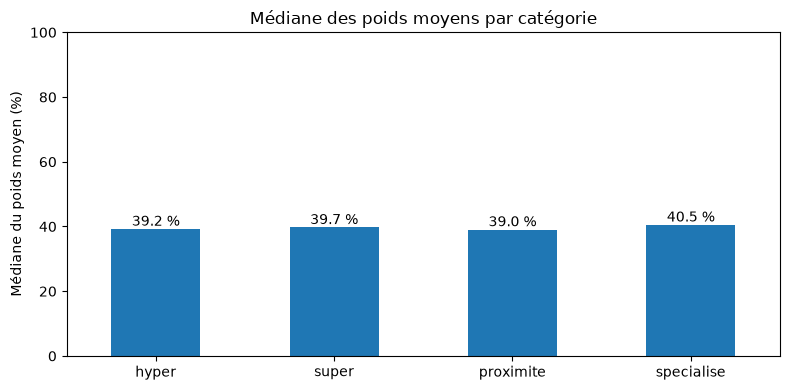

In [19]:
ratios = pd.DataFrame({
    cat: dvf[f"acces_{cat}"] / dvf[f"nb_rayon_{cat}"].replace(0, float("nan"))
    for cat in categories
})

valeurs = ratios.median() * 100

ax = valeurs.plot(kind="bar", figsize=(8, 4))
ax.bar_label(ax.containers[0], fmt="%.1f %%")

plt.title("Médiane des poids moyens par catégorie")
plt.ylabel("Médiane du poids moyen (%)")
plt.xlabel("")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Les résultats sont très proche. Cela signifie que, pour un logement typique, chaque commerce accessible contribue en moyenne à environ 0,4 dans l'indice dégressif, contre 1 avec la frontière nette.

La distance réduit donc le poids des commerces de façon assez similaire entre les catégories.

### Comparaison de l'accessibilité aux supermarchés selon la densité

Pour chaque niveau de densité (DENS7), on calcule l'accessibilité médiane aux supermarchés avec les deux méthodes. On fixe ensuite la valeur des grands centres urbains (DENS7 = 1) à 100, pour comparer les autres niveaux de densité sur une même base.

,Frontière nette,Frontière dégressive
DENS7,,
1,100.0,100.0
2,50.0,72.9
3,33.3,55.6
4,33.3,41.0
5,33.3,37.7
6,33.3,27.8
7,16.7,16.4


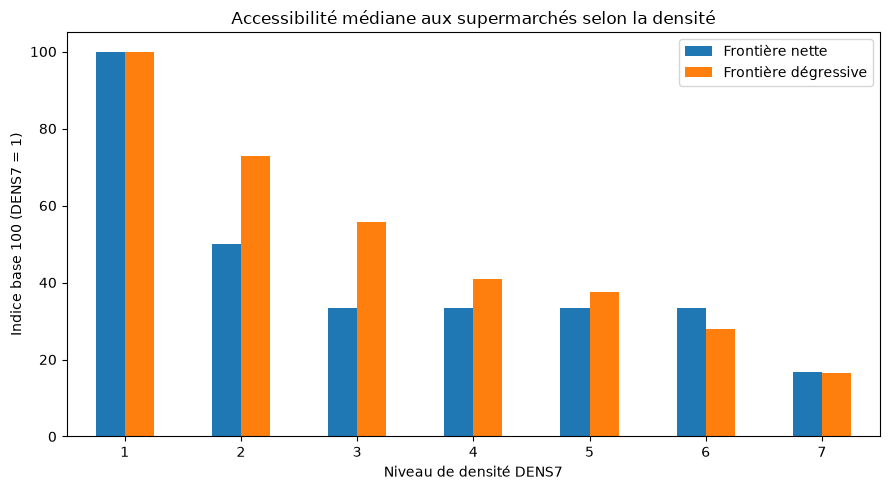

In [20]:
par_densite = dvf.groupby("DENS7")[["nb_rayon_super", "acces_super"]].median()

par_densite.columns = ["Frontière nette", "Frontière dégressive"]

par_densite = par_densite / par_densite.loc["1"] * 100

display(par_densite.round(1))

par_densite.plot(kind="bar", figsize=(9, 5))

plt.title("Accessibilité médiane aux supermarchés selon la densité")
plt.xlabel("Niveau de densité DENS7")
plt.ylabel("Indice base 100 (DENS7 = 1)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Avec les deux méthodes, l'accessibilité aux supermarchés diminue avec la densité baisse.

Cependant, la baisse varie selon la méthode. La pondération par la distance modifie les écarts d'accessibilité entre les territoires, surtout pour les niveaux de densité intermédiaires. 

Dans les zones moins denses, les rayons adaptés à la densité peuvent être plus grands : un supermarché peut donc être plus éloigné en mètres, mais conserver un poids élevé dans l'indice dégressif. Cela pourrait expliquer pourquoi l'accessibilité diminue moins fortement avec la frontière dégressive dans certaines zones intermédiaires.

In [21]:
from src import resultats

dvf.to_parquet(config.DOSSIER_DONNEES / "dvf_enrichi_2025.parquet")
print("Ventes enrichies :", len(dvf))

resultats.ecrire({
    "rayons": rayons.round(0).reset_index(),
    "prix_par_densite": resultats.prix_par_densite(dvf),
    "distances_par_densite": resultats.distances_par_densite(dvf, categories),
    "departements": resultats.resume_departements(dvf),
    "prix_par_tranche": resultats.prix_par_tranche(dvf, categories),
    "prix_par_tranche_hors_paris": resultats.prix_par_tranche(dvf, categories, exclure_paris=True),
}, config.DOSSIER_TABLES)

Ventes enrichies : 810517
rayons.csv : 7 lignes
prix_par_densite.csv : 14 lignes
distances_par_densite.csv : 7 lignes
departements.csv : 93 lignes
prix_par_tranche.csv : 140 lignes
prix_par_tranche_hors_paris.csv : 140 lignes
